# Data Cleaning — Oasis Infobyte Level 1 Task 3



In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd()
if not (BASE_DIR / 'AB_NYC_2019.csv').exists() and (BASE_DIR / 'DataAnalytics-L1-CleaningData' / 'AB_NYC_2019.csv').exists():
    BASE_DIR = BASE_DIR / 'DataAnalytics-L1-CleaningData'
DATA_PATH = BASE_DIR / 'AB_NYC_2019.csv'
OUTPUT_DIR = BASE_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('colorblind')
print(f'Dataset: {DATA_PATH.resolve()}')
print(f'Outputs: {OUTPUT_DIR.resolve()}')

Dataset: C:\Users\penta\Downloads\OIBSIP\DataAnalytics-L1-CleaningData\AB_NYC_2019.csv
Outputs: C:\Users\penta\Downloads\OIBSIP\DataAnalytics-L1-CleaningData\outputs


## Initial inspection and quality report



In [17]:
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.head())

missing_before = raw.isna().sum()
quality_before = pd.DataFrame({
    'dtype_before': raw.dtypes.astype(str),
    'missing_before': missing_before,
    'missing_pct_before': (missing_before / len(raw) * 100).round(2),
    'unique_non_null': raw.nunique(dropna=True),
})
display(quality_before)
print('Exact duplicate rows:', int(raw.duplicated().sum()))
print('Duplicate listing IDs:', int(raw['id'].duplicated().sum()))
print('Missing values:', missing_before[missing_before.gt(0)].to_dict())
print('Whitespace around nonmissing listing names:', int(raw['name'].dropna().ne(raw['name'].dropna().str.strip()).sum()))
print('Whitespace around other text fields:', {c: int(raw[c].dropna().ne(raw[c].dropna().str.strip()).sum()) for c in ['host_name','neighbourhood_group','neighbourhood','room_type']})
print('Neighbourhood groups:', sorted(raw['neighbourhood_group'].dropna().unique().tolist()))
print('Room types:', sorted(raw['room_type'].dropna().unique().tolist()))
print('Date strings failing YYYY-MM-DD parse (includes missing):', int(pd.to_datetime(raw['last_review'], format='%Y-%m-%d', errors='coerce').isna().sum()))
print('Range checks:', {
    'price < 0': int(raw['price'].lt(0).sum()),
    'price == 0': int(raw['price'].eq(0).sum()),
    'minimum_nights < 1': int(raw['minimum_nights'].lt(1).sum()),
    'number_of_reviews < 0': int(raw['number_of_reviews'].lt(0).sum()),
    'availability_365 outside [0,365]': int((~raw['availability_365'].between(0,365)).sum()),
    'latitude outside broad NYC check [40,41]': int((~raw['latitude'].between(40,41)).sum()),
    'longitude outside broad NYC check [-75,-73]': int((~raw['longitude'].between(-75,-73)).sum()),
})
print('reviews_per_month missing while number_of_reviews > 0:', int((raw['reviews_per_month'].isna() & raw['number_of_reviews'].gt(0)).sum()))
print('last_review missing while number_of_reviews > 0:', int((raw['last_review'].isna() & raw['number_of_reviews'].gt(0)).sum()))

Shape: (48895, 16)
Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


,dtype_before,missing_before,missing_pct_before,unique_non_null
id,int64,0,0.00,48895
name,str,16,0.03,47905
host_id,int64,0,0.00,37457
host_name,str,21,0.04,11452
neighbourhood_group,str,0,0.00,5
neighbourhood,str,0,0.00,221
latitude,float64,0,0.00,19048
longitude,float64,0,0.00,14718
room_type,str,0,0.00,3
price,int64,0,0.00,674


Exact duplicate rows: 0
Duplicate listing IDs: 0
Missing values: {'name': 16, 'host_name': 21, 'last_review': 10052, 'reviews_per_month': 10052}
Whitespace around nonmissing listing names: 238
Whitespace around other text fields: {'host_name': 0, 'neighbourhood_group': 0, 'neighbourhood': 0, 'room_type': 0}
Neighbourhood groups: ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']
Room types: ['Entire home/apt', 'Private room', 'Shared room']
Date strings failing YYYY-MM-DD parse (includes missing): 10052
Range checks: {'price < 0': 0, 'price == 0': 11, 'minimum_nights < 1': 0, 'number_of_reviews < 0': 0, 'availability_365 outside [0,365]': 0, 'latitude outside broad NYC check [40,41]': 0, 'longitude outside broad NYC check [-75,-73]': 0}
reviews_per_month missing while number_of_reviews > 0: 0
last_review missing while number_of_reviews > 0: 0


## Cleaning decisions


In [18]:
# IQR screening on numeric measures; IDs and coordinates are not interpreted as outlier measures.
outlier_columns = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count']
outlier_rows = []
for column in outlier_columns:
    values = raw[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = raw[column].notna() & ((raw[column] < lower) | (raw[column] > upper))
    outlier_rows.append({
        'column': column, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'lower_fence': lower, 'upper_fence': upper,
        'outlier_count': int(mask.sum()), 'outlier_pct_of_nonmissing': round(mask.sum() / values.size * 100, 2),
        'minimum': values.min(), 'maximum': values.max(), 'treatment': 'Retain; IQR flags are not proof of invalid data.'
    })
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report.round(2))
outlier_report.to_csv(OUTPUT_DIR / 'iqr_outlier_report.csv', index=False)

,column,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct_of_nonmissing,minimum,maximum,treatment
0,price,69.00,175.00,106.00,-90.00,334.00,2972,6.08,0.00,10000.0,Retain; IQR flags are not proof of invalid data.
1,minimum_nights,1.00,5.00,4.00,-5.00,11.00,6607,13.51,1.00,1250.0,Retain; IQR flags are not proof of invalid data.
2,number_of_reviews,1.00,24.00,23.00,-33.50,58.50,6021,12.31,0.00,629.0,Retain; IQR flags are not proof of invalid data.
3,reviews_per_month,0.19,2.02,1.83,-2.56,4.77,1793,4.62,0.01,58.5,Retain; IQR flags are not proof of invalid data.
4,calculated_host_listings_count,1.00,2.00,1.00,-0.50,3.50,7081,14.48,1.00,327.0,Retain; IQR flags are not proof of invalid data.


### Outlier screening chart
IQR fences are screening thresholds, not validity rules. Counts below show how many listings fall outside each column's fence; these values remain unchanged in the cleaned file.


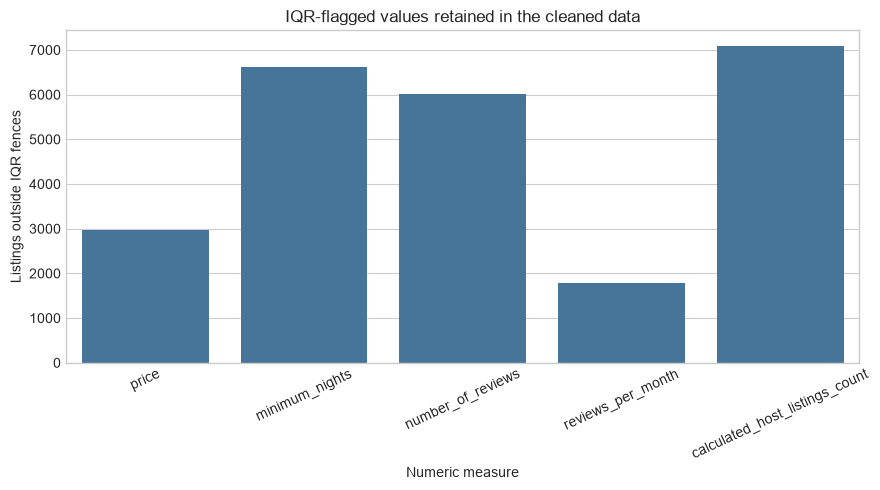

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=outlier_report, x='column', y='outlier_count', color='#3977a8', ax=ax)
ax.set(title='IQR-flagged values retained in the cleaned data', xlabel='Numeric measure', ylabel='Listings outside IQR fences')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'iqr_outlier_counts.png', dpi=160, bbox_inches='tight')
plt.show()

## Apply cleaning and compare before/after
No rows are removed: this dataset has no exact duplicate listing records, and suspicious or extreme values are retained unless they violate a verified rule. Missing-value treatment is limited to fields whose meaning is supported by the data. A per-column report compares counts, missingness, and in-memory data types before and after cleaning.


In [13]:
cleaned = raw.copy()
text_columns = ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type']
for column in text_columns:
    cleaned[column] = cleaned[column].str.strip()
cleaned['name'] = cleaned['name'].fillna('[Missing listing name]')
cleaned['host_name'] = cleaned['host_name'].fillna('[Unknown host]')

parsed_review_date = pd.to_datetime(cleaned['last_review'], format='%Y-%m-%d', errors='coerce')
parse_failures = int((cleaned['last_review'].notna() & parsed_review_date.isna()).sum())
cleaned['last_review'] = parsed_review_date
# In this source, every missing monthly review rate belongs to a zero-review listing.
assert (cleaned.loc[cleaned['reviews_per_month'].isna(), 'number_of_reviews'] == 0).all()
cleaned['reviews_per_month'] = cleaned['reviews_per_month'].fillna(0.0)

before_rows, after_rows = len(raw), len(cleaned)
missing_after = cleaned.isna().sum()
quality_comparison = pd.DataFrame({
    'dtype_before': raw.dtypes.astype(str),
    'dtype_after': cleaned.dtypes.astype(str),
    'missing_before': raw.isna().sum(),
    'missing_after': missing_after,
})
quality_comparison['missing_reduction'] = quality_comparison['missing_before'] - quality_comparison['missing_after']
quality_comparison['rows_before'] = before_rows
quality_comparison['rows_after'] = after_rows
quality_comparison['duplicate_rows_before'] = int(raw.duplicated().sum())
quality_comparison['duplicate_rows_after'] = int(cleaned.duplicated().sum())
display(quality_comparison)
quality_comparison.to_csv(OUTPUT_DIR / 'before_after_quality_report.csv')
print(f'Rows: {before_rows:,} before -> {after_rows:,} after')
print(f'Exact duplicates: {int(raw.duplicated().sum())} before -> {int(cleaned.duplicated().sum())} after')
print('Nonmissing review-date parse failures:', parse_failures)
print('Missing-value counts after cleaning:', missing_after[missing_after.gt(0)].to_dict())

,dtype_before,dtype_after,missing_before,missing_after,missing_reduction,rows_before,rows_after,duplicate_rows_before,duplicate_rows_after
id,int64,int64,0,0,0,48895,48895,0,0
name,str,str,16,0,16,48895,48895,0,0
host_id,int64,int64,0,0,0,48895,48895,0,0
host_name,str,str,21,0,21,48895,48895,0,0
neighbourhood_group,str,str,0,0,0,48895,48895,0,0
neighbourhood,str,str,0,0,0,48895,48895,0,0
latitude,float64,float64,0,0,0,48895,48895,0,0
longitude,float64,float64,0,0,0,48895,48895,0,0
room_type,str,str,0,0,0,48895,48895,0,0
price,int64,int64,0,0,0,48895,48895,0,0


Rows: 48,895 before -> 48,895 after
Exact duplicates: 0 before -> 0 after
Nonmissing review-date parse failures: 0
Missing-value counts after cleaning: {'last_review': 10052}


## Export and validation
The cleaned dataset is written separately; the original CSV remains unchanged. The exported date is formatted as ISO `YYYY-MM-DD`, with unreviewed listings left blank. Assertions verify row preservation, listing-key uniqueness, missing-value decisions, valid ranges, and the absence of duplicate rows.


In [19]:
assert parse_failures == 0
assert len(cleaned) == len(raw)
assert not cleaned.duplicated().any()
assert cleaned['id'].is_unique
assert cleaned['name'].notna().all() and cleaned['host_name'].notna().all()
assert cleaned['reviews_per_month'].notna().all()
assert (cleaned['minimum_nights'] >= 1).all()
assert cleaned['availability_365'].between(0, 365).all()
assert cleaned['latitude'].between(40, 41).all() and cleaned['longitude'].between(-75, -73).all()
assert cleaned.loc[cleaned['number_of_reviews'].eq(0), 'reviews_per_month'].eq(0).all()

export = cleaned.copy()
export['last_review'] = export['last_review'].dt.strftime('%Y-%m-%d')
cleaned_path = OUTPUT_DIR / 'cleaned_data.csv'
export.to_csv(cleaned_path, index=False)
assert cleaned_path.exists() and cleaned_path.stat().st_size > 0
# Read-back verification checks schema, row count, missingness, and key constraints.
round_trip = pd.read_csv(cleaned_path)
assert len(round_trip) == len(cleaned)
assert round_trip['id'].is_unique
assert round_trip['name'].notna().all() and round_trip['host_name'].notna().all()
assert round_trip['reviews_per_month'].notna().all()
print(f'Validation passed. Cleaned CSV: {cleaned_path.resolve()} ({cleaned_path.stat().st_size:,} bytes)')
print('Date is exported in ISO format; listings without reviews have blank last_review and reviews_per_month = 0.')

Validation passed. Cleaned CSV: C:\Users\penta\Downloads\OIBSIP\DataAnalytics-L1-CleaningData\outputs\cleaned_data.csv (7,157,114 bytes)
Date is exported in ISO format; listings without reviews have blank last_review and reviews_per_month = 0.


## Findings and limitations

The source contains no exact duplicate rows or duplicate listing IDs. Missing listing and host names are limited to 16 and 21 rows. The 10,052 listings without a review date also have no reviews; their missing monthly review rate is therefore represented as zero. There are 11 listings with a price of zero, which are retained and disclosed because the dataset alone cannot confirm whether these are mistakes.

IQR screening flags high values in several measures (including price and minimum nights), but these are retained as potentially genuine listing characteristics. IQR does not detect every data issue and cannot establish that a value is wrong. The broad coordinate bounds only catch gross geographic errors and are not a full address-level geospatial validation. This is a static 2019 snapshot; it does not establish current listing status or current market prices.


## References

- Dataset title/schema reference: [New York City Airbnb Open Data (Kaggle)](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data).
- pandas documentation: [Missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html), [DataFrame duplicates](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html).
